# 1. Affichage & importation des bibliothèques

In [123]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import matplotlib.pyplot as plt
import plotly.express as px
import ipywidgets as widgets

## **Importation du csv**

In [124]:
df = pd.read_csv("hotel_bookings.csv")

In [125]:
pd.set_option('display.max_columns', None)  # Affiche toutes les colonnes

## **Affichage**

In [126]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## **Information sur les variables**

# 2. Nettoyage & mise en forme du jeu de données

In [127]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## **Rennommage des colonnes**

In [128]:
colonnes_fr = {
    "hotel": "hotel",
    "is_canceled": "est_annule",
    "lead_time": "delai_reservation_jours",
    "arrival_date_year": "annee_arrivee",
    "arrival_date_month": "mois_arrivee",
    "arrival_date_week_number": "semaine_arrivee",
    "arrival_date_day_of_month": "jour_arrivee",
    "stays_in_weekend_nights": "nuits_weekend",
    "stays_in_week_nights": "nuits_semaine",
    "adults": "adultes",
    "children": "enfants",
    "babies": "bebes",
    "meal": "formule_repas",
    "country": "pays",
    "market_segment": "segment_marche",
    "distribution_channel": "canal_distribution",
    "is_repeated_guest": "client_fidele",
    "previous_cancellations": "annulations_precedentes",
    "previous_bookings_not_canceled": "reservations_precedentes_non_annulees",
    "reserved_room_type": "type_chambre_reservee",
    "assigned_room_type": "type_chambre_attribuee",
    "booking_changes": "nb_modifications",
    "deposit_type": "type_acompte",
    "agent": "id_agent",
    "company": "id_entreprise",
    "days_in_waiting_list": "jours_liste_attente",
    "customer_type": "type_client",
    "adr": "prix_moyen_nuit",
    "required_car_parking_spaces": "places_parking",
    "total_of_special_requests": "nb_demandes_speciales",
    "reservation_status": "statut_reservation",
    "reservation_status_date": "date_statut_reservation",
}

df = df.rename(columns=colonnes_fr)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   hotel                                  119390 non-null  str    
 1   est_annule                             119390 non-null  int64  
 2   delai_reservation_jours                119390 non-null  int64  
 3   annee_arrivee                          119390 non-null  int64  
 4   mois_arrivee                           119390 non-null  str    
 5   semaine_arrivee                        119390 non-null  int64  
 6   jour_arrivee                           119390 non-null  int64  
 7   nuits_weekend                          119390 non-null  int64  
 8   nuits_semaine                          119390 non-null  int64  
 9   adultes                                119390 non-null  int64  
 10  enfants                                119386 non-null  float64
 11

## **Forme du dataset**

In [129]:
df.shape

(119390, 32)

##### Volume présent de 119390 lignes, 32 colonnes, avec des données s'étalant de juillet 2015 et août 2017.

## **Valeurs manquantes**

In [130]:
df.isna().sum()

hotel                                         0
est_annule                                    0
delai_reservation_jours                       0
annee_arrivee                                 0
mois_arrivee                                  0
semaine_arrivee                               0
jour_arrivee                                  0
nuits_weekend                                 0
nuits_semaine                                 0
adultes                                       0
enfants                                       4
bebes                                         0
formule_repas                                 0
pays                                        488
segment_marche                                0
canal_distribution                            0
client_fidele                                 0
annulations_precedentes                       0
reservations_precedentes_non_annulees         0
type_chambre_reservee                         0
type_chambre_attribuee                  

##### Présence de valeurs manquantes dans les variables **_pays_**, **_id_agent_** et **_id_entreprise_**. A supprimer, renommer ou encoder dans la partie de machine learning.

## **Suppression valeurs manquantes variable _pays_ (????)**

## **Mise en évidence valeurs manquantes variable _id_agent_**

In [131]:
print("Répartition des NaN id_agent par segment_marche")
df[df['id_agent'].isna()]['segment_marche'].value_counts()

Répartition des NaN id_agent par segment_marche


segment_marche
Direct           6007
Corporate        4594
Groups           4148
Complementary     640
Offline TA/TO     389
Online TA         348
Aviation          212
Undefined           2
Name: count, dtype: int64

In [132]:
print("Répartition des NaN id_agent par canal_distribution")
df[df['id_agent'].isna()]['canal_distribution'].value_counts()

Répartition des NaN id_agent par canal_distribution


canal_distribution
Direct       7625
Corporate    5543
TA/TO        3167
Undefined       3
GDS             2
Name: count, dtype: int64

##### La répartition des NaN montre que cela ne signifie pas forcément l'absence d'agent mais plutôt une information non renseigné.

##### Pour le traitement de cette variable, on peux utiliser une méthode pandas qui signifie "not NaN" (not available) et qui renvoie une series de booléens (True si la valeur est renseignée (= pas NaN) et False si la valeur est NaN. Par la suite on convertit les booléens en entiers (True → 1 et False → 0). C'est ce qu'on appelle un encodage binaire ou dummy variable. On crée une nouvelle colonne dans le DataFrame, nommée **_agent_renseigne_**, et on y stocke le résultat. La méthode .fillna(valeur) remplace toutes les valeurs NaN par la valeur qu'on lui passe. On utilise -1 exprès, parce que 0 pourrait être un vrai ID d'agent (les ID commencent à 1, mais rien ne garantit que 0 n'existe pas un jour). et -1 est impossible dans les données réelles (les ID sont tous positifs). C'est une valeur sentinelle = "valeur spéciale qui signifie NaN".

##### C'est une convention très répandue en data science : -1, -999, -9999 sont des valeurs réservées pour signifier "manquant". Si on fait seuelement la ligne 2, on perdrait l'information du NaN (comment savoir si -1 était un NaN ou un vrai agent ?), et si on fait seulement la ligne 1, on garderait des NaN qui gêneraient les calculs.

## **Mise en évidence des valeurs manquantes variable _id_entreprise_**

In [133]:
df["id_entreprise"]

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
119385   NaN
119386   NaN
119387   NaN
119388   NaN
119389   NaN
Name: id_entreprise, Length: 119390, dtype: float64

## **Suppression des doublons**

In [134]:
df.duplicated().value_counts()

False    87396
True     31994
Name: count, dtype: int64

In [135]:
df = df.drop_duplicates()

In [136]:
sans_client = (df["adultes"].fillna(0) == 0) & (df["enfants"].fillna(0) + df["bebes"] == 0)
sans_nuit   = (df["nuits_semaine"] + df["nuits_weekend"]) == 0
prix_nul    = df["prix_moyen_nuit"] == 0

print("Prix nuls au total :", prix_nul.sum())                                    
print("Prix nuls inexploitables (sans client ou sans nuit) :", (prix_nul & (sans_client | sans_nuit)).sum())
print("Prix nuls gardés :", (prix_nul & ~sans_client & ~sans_nuit).sum())         

Prix nuls au total : 1778
Prix nuls inexploitables (sans client ou sans nuit) : 726
Prix nuls gardés : 1052


# 3. Dictionnaire et informations sur variables

## **Type d'établissement**

### Signification : 

Nombre et répartition des établissements.

In [137]:
df["hotel"].unique()

<ArrowStringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str

In [138]:
df["hotel"].value_counts()

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

In [139]:
df["hotel"].value_counts().sum()

np.int64(87396)

## **Segments par marchés**

### Signification des canaux de distribution (Segments de marche)

Voici la description des colonnes de votre jeu de donnees :

*   **Direct** : Reservations effectuees directement par le client. Cela inclut le site web de hotel, les appels ou les e-mails, sans aucun intermediaire.
*   **Corporate** : Reservations pour les voyages affaires. Ce sont des contrats negocies directement avec des entreprises pour loger leurs employes.
*   **Online TA** (Online Travel Agency) : Reservations via des agences en ligne comme Booking ou Expedia.
*   **Offline TA/TO** (Travel Agency / Tour Operator) : Reservations via des agences physiques traditionnelles ou des voyagistes.
*   **Complementary** : Chambres offertes gratuitement (invitations, fidelite ou compensations).
*   **Groups** : Reservations groupees pour des evenements, des mariages ou des seminaires (plusieurs chambres reservees ensemble).
*   **Undefined** : Donnees manquantes. Le canal origine est inconnu.
*   **Aviation** : Reservations pour les equipages des compagnies aeriennes pendant leurs escales.


In [140]:
df["segment_marche"].value_counts()

segment_marche
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

In [141]:
df["segment_marche"].value_counts().sum()

np.int64(87396)

In [142]:
undefined_marche = df["segment_marche"] == "Undefined"

In [143]:
df[undefined_marche]

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation
40600,City Hotel,1,2,2015,August,32,3,1,0,2,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40679,City Hotel,1,1,2015,August,32,5,0,2,3,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04


## **Canaux de distribution**

### Signification des segments de marche (Version alternative)

Voici la description des colonnes de votre deuxieme jeu de donnees :

*   **Direct** : Reservations effectuees en direct par le client via le site web officiel, par telephone ou par e-mail, sans payer de commission a un intermediaire.
*   **Corporate** : Reservations liees aux voyages affaires, effectuees sous des tarifs negocies pour le compte entreprises.
*   **TA/TO** (Travel Agencies / Tour Operators) : Regroupement global des agences de voyage et des voyagistes, incluant a la fois les acteurs en ligne et physiques.
*   **Undefined** : Donnees non specifiees ou manquantes lors de la saisie de la reservation.
*   **GDS** (Global Distribution System) : Reservations via les grands reseaux informatiques utilises par les agences de voyage professionnelles comme Amadeus, Sabre ou Galileo.



In [144]:
df["canal_distribution"].value_counts()

canal_distribution
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

In [145]:
df["canal_distribution"].value_counts().sum()

np.int64(87396)

In [146]:
df["canal_distribution"].unique()

<ArrowStringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

In [147]:
undefined_distribution = df["canal_distribution"] == "Undefined"

In [148]:
df[undefined_distribution]

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation
14594,Resort Hotel,0,103,2015,July,28,5,2,3,2,1.0,0,HB,PRT,Direct,Undefined,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,112.7,1,2,Check-Out,2015-07-10
40600,City Hotel,1,2,2015,August,32,3,1,0,2,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,NaN,0,BB,PRT,Direct,Undefined,0,0,0,B,B,0,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,NaN,0,BB,PRT,Online TA,Undefined,0,0,0,B,B,0,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


## **Types de Pension**

### Signification des types de restauration (Meal Packages)

Voici la description des colonnes liees aux formules de repas :

*   **BB** (Bed and Breakfast) : Formule nuit et petit-dejeuner. Seul le premier repas de la journee est inclus dans le prix.
*   **FB** (Full Board) : Pension complete. Le petit-dejeuner, le dejeuner et le diner sont inclus dans le prix de la chambre.
*   **HB** (Half Board) : Demi-pension. Le petit-dejeuner et un repas principal (gourmandise du soir ou dejeuner) sont inclus.
*   **SC** (Self Catering) : Sans repas (ou dejeuner non compris). Le client cuisine lui-meme ou achete sa nourriture, aucune formule de restauration est incluse.
*   **Undefined** : Formule non specifiee ou manquante dans la base de donnees.




In [149]:
df["formule_repas"].value_counts()

formule_repas
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64

In [150]:
df["formule_repas"].value_counts().sum()

np.int64(87396)

## **Statuts de réservation**

### Signification : 

Nombre et répartition des statuts de réservation.

In [151]:
df["statut_reservation"].value_counts()

statut_reservation
Check-Out    63371
Canceled     23011
No-Show       1014
Name: count, dtype: int64

## **Demandes spéciales**

### Signification : 

Nombre et répartition du nombres de demandes spéciales.

In [152]:
df["nb_demandes_speciales"].unique()

array([0, 1, 3, 2, 4, 5])

In [153]:
df["nb_demandes_speciales"].value_counts()

nb_demandes_speciales
0    43894
1    29017
2    11812
3     2317
4      320
5       36
Name: count, dtype: int64

In [154]:
df["nb_demandes_speciales"].value_counts().sum()

np.int64(87396)

## **Places de parking**

### Signification : 

Nombre et répartition des places de parking les plus demandées.

In [155]:
df["places_parking"].unique()

array([0, 1, 2, 8, 3])

In [156]:
df["places_parking"].value_counts()

places_parking
0    80083
1     7280
2       28
3        3
8        2
Name: count, dtype: int64

In [157]:
df["places_parking"].value_counts().sum()

np.int64(87396)

## **Type de client**

### Signification des types de clients (Customer Types)

Voici la description des colonnes liees aux profils et segments de clients :

*   **Transient** : Client de passage. Il sagit de clients individuels qui reservent de maniere isolee, sans contrat a long terme et hors du cadre dun groupe ou dune offre speciale.
*   **Contract** : Client sous contrat. La reservation est associee a un accord specifique ou une offre recurrente (comme les equipages de compagnies aeriennes ou les abonnements corporatifs).
*   **Transient-Party** : Client de passage lie a un groupe temporaire. Il sagit de clients individuels mais dont la reservation est rattachee a une autre reservation principale (par exemple via une agence de voyage).
*   **Group** : Client de groupe. La reservation fait partie dun bloc de chambres reservees ensemble pour un evenement specifique (comme un seminaire ou un mariage).


In [158]:
df["type_client"].unique()

<ArrowStringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

## **Jours de liste d'attente**

### Signification : 

Nombre et répartition des jours de liste d'attente.

In [159]:
df["jours_liste_attente"].value_counts()

jours_liste_attente
0      86536
63        53
87        25
44        23
15        22
       ...  
81         1
92         1
74         1
167        1
36         1
Name: count, Length: 128, dtype: int64

In [160]:
df["jours_liste_attente"].value_counts().sum()

np.int64(87396)

## **Entreprise Cliente**

### Signification : 

Nombre et répartition des entreprises les plus prolifiques.

In [161]:
df["id_entreprise"].nunique()

352

In [162]:
df["id_entreprise"].value_counts()

id_entreprise
40.0     851
223.0    503
45.0     238
153.0    206
154.0    133
        ... 
483.0      1
489.0      1
229.0      1
481.0      1
497.0      1
Name: count, Length: 352, dtype: int64

In [163]:
df["id_entreprise"].value_counts().sum()

np.int64(5259)

## **Les Agents**

### Signification : 

Nombre et répartition des agents les plus prolifiques.

In [164]:
df["id_agent"].nunique()

333

In [165]:
df["id_agent"].value_counts()

id_agent
9.0      28759
240.0    13028
14.0      3349
7.0       3300
250.0     2779
         ...  
408.0        1
388.0        1
453.0        1
480.0        1
449.0        1
Name: count, Length: 333, dtype: int64

In [166]:
df["id_agent"].value_counts().sum()

np.int64(75203)

## **Type d'Acompte**

### Signification des types de depot (Deposit Types)

Voici la description des colonnes liees aux conditions de garantie et de remboursement :

*   **No Deposit** : Aucun depot requis. Le client ne paye rien en avance et peut annuler selon les conditions standards sans prelevement immediat.
*   **Refundable** : Depot remboursable. Le client paye une somme en avance, mais cette somme est restituee si annulation respecte les delais fixes.
*   **Non Refund** : Depot non remboursable. La totalite ou une partie du sejour est debitee immediatement et reste acquise a hotel en cas annulation.


In [167]:
df["type_acompte"].unique()

<ArrowStringArray>
['No Deposit', 'Refundable', 'Non Refund']
Length: 3, dtype: str

In [168]:
df["type_acompte"].value_counts()

type_acompte
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64

In [169]:
df["type_acompte"].value_counts().sum()

np.int64(87396)

## **Les Modifications**

### Signification : 

Nombre et répartition des types d' Acompte.

In [170]:
df["nb_modifications"].value_counts()

nb_modifications
0     71494
1     10902
2      3508
3       875
4       356
5       116
6        59
7        31
8        17
9         8
10        6
13        5
14        5
15        3
17        2
16        2
12        2
11        2
20        1
21        1
18        1
Name: count, dtype: int64

In [171]:
df["nb_modifications"].value_counts().sum()

np.int64(87396)

## **Types Chambres réservées et attribuées**

### Signification : 

Nombre et répartition des types de Chambres réservées ou attribuées.

***reservée***

In [172]:
df["type_chambre_reservee"].unique()

<ArrowStringArray>
['C', 'A', 'D', 'E', 'G', 'F', 'H', 'L', 'P', 'B']
Length: 10, dtype: str

In [173]:
df["type_chambre_reservee"].value_counts()

type_chambre_reservee
A    56552
D    17398
E     6049
F     2823
G     2052
B      999
C      915
H      596
L        6
P        6
Name: count, dtype: int64

In [174]:
df["type_chambre_reservee"].value_counts().sum()

np.int64(87396)

***Attribuée***

In [175]:
df["type_chambre_attribuee"].unique()

<ArrowStringArray>
['C', 'A', 'D', 'E', 'G', 'F', 'I', 'B', 'H', 'P', 'L', 'K']
Length: 12, dtype: str

df["type_chambre_attribuee"].value_counts()

In [176]:
df["type_chambre_attribuee"].value_counts().sum()

np.int64(87396)

## **Historiques de réservations confirmées**

### Signification : 

Nombre et répartition des historiques de réservations confirmées

In [177]:
df["reservations_precedentes_non_annulees"].value_counts()

reservations_precedentes_non_annulees
0     83851
1      1482
2       580
3       331
4       228
      ...  
68        1
69        1
70        1
71        1
72        1
Name: count, Length: 73, dtype: int64

In [178]:
df["reservations_precedentes_non_annulees"].value_counts().sum()

np.int64(87396)

## **Historique d'annulations**

### Signification : 

Nombre et répartition des historiques d'annulations.

In [179]:
df["annulations_precedentes"].value_counts()

annulations_precedentes
0     85711
1      1407
2       112
3        61
4        30
11       27
5        19
6        17
13        4
25        2
24        2
26        1
14        1
19        1
21        1
Name: count, dtype: int64

In [180]:
df["annulations_precedentes"].value_counts().sum()

np.int64(87396)

## **Prix moyen d'une nuit**

### Signification : 

Nombre et répartition des prix par nuit en moyenne.

In [181]:
df["prix_moyen_nuit"].value_counts().sum()

np.int64(87396)

In [182]:
df["prix_moyen_nuit"].value_counts()

prix_moyen_nuit
0.00      1778
75.00     1320
65.00     1260
48.00      878
85.00      858
          ... 
134.82       1
91.02        1
266.75       1
209.25       1
157.71       1
Name: count, Length: 8879, dtype: int64

In [183]:
(df['prix_moyen_nuit'] == 0).sum()

np.int64(1778)

In [184]:
(df['prix_moyen_nuit'] == 0).sum()

np.int64(1778)

In [185]:
df["prix_moyen_nuit"].describe()

count    87396.000000
mean       106.337246
std         55.013953
min         -6.380000
25%         72.000000
50%         98.100000
75%        134.000000
max       5400.000000
Name: prix_moyen_nuit, dtype: float64

***Attention*** On a une valeur négative à traiter, suppression de la valeur du dataset.

In [186]:
negatif = df["prix_moyen_nuit"] < 0
df[negatif]

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,0.0,0,BB,GBR,Groups,Direct,1,0,2,A,H,2,No Deposit,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [187]:
df.drop(df[negatif].index,inplace=True)

Vérification après suppression de la valeur négative on 0 en minimun

In [188]:
print("Prix égal à zéro :", (df["prix_moyen_nuit"] == 0).sum())
print("Prix négatifs :", (df["prix_moyen_nuit"] < 0).sum())
print("Prix supérieurs à 5 000 :", (df["prix_moyen_nuit"] > 5000).sum())

display(df["prix_moyen_nuit"].describe())

Prix égal à zéro : 1778
Prix négatifs : 0
Prix supérieurs à 5 000 : 1


count    87395.000000
mean       106.338536
std         55.012947
min          0.000000
25%         72.000000
50%         98.100000
75%        134.000000
max       5400.000000
Name: prix_moyen_nuit, dtype: float64

## **Valeurs numériques**

In [189]:
df_numerique = df.select_dtypes(include=['number'])
print(df_numerique.shape[1])
print(df_numerique.columns.tolist())

20
['est_annule', 'delai_reservation_jours', 'annee_arrivee', 'semaine_arrivee', 'jour_arrivee', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'client_fidele', 'annulations_precedentes', 'reservations_precedentes_non_annulees', 'nb_modifications', 'id_agent', 'id_entreprise', 'jours_liste_attente', 'prix_moyen_nuit', 'places_parking', 'nb_demandes_speciales']


##### Présence de 20 colonnes numériques.

## **Heatmap des valeurs numériques**

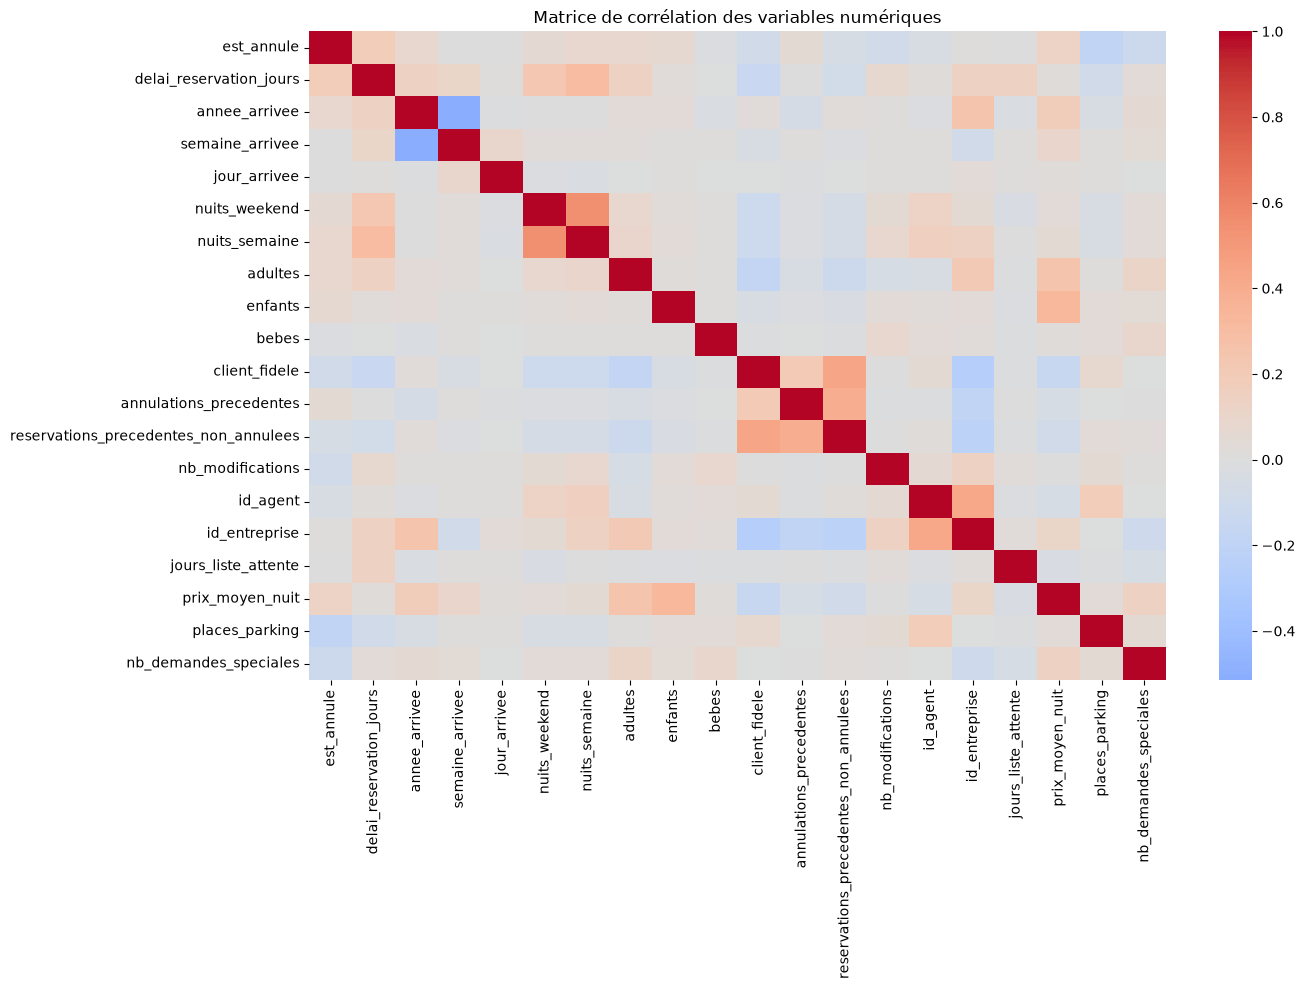

In [190]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df_numerique.corr(),
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

## **Détection des valeurs abbérantes**

***Variable _prix_moyen_nuit_***

<Axes: >

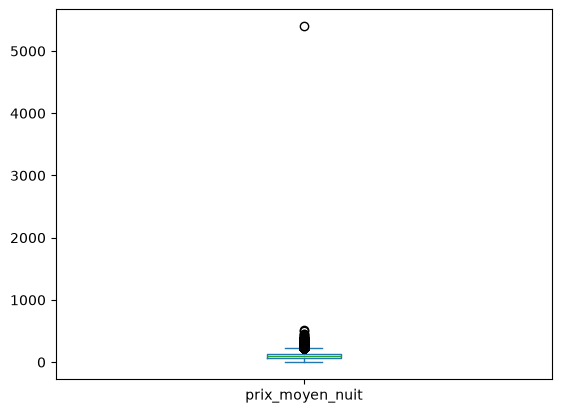

In [191]:
df["prix_moyen_nuit"].plot.box()

In [192]:
aberrant = df["prix_moyen_nuit"] > 5000
df[aberrant]

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation
48515,City Hotel,1,35,2016,March,13,25,0,1,2,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,1,Non Refund,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016-02-19


In [193]:
display(df.loc[aberrant, ["hotel", "prix_moyen_nuit"]])
print("Nombre de prix supérieurs à 5 000 :", aberrant.sum())

,hotel,prix_moyen_nuit
48515,City Hotel,5400.0


Nombre de prix supérieurs à 5 000 : 1


In [194]:
df.drop(df[aberrant].index, inplace=True)

<Axes: >

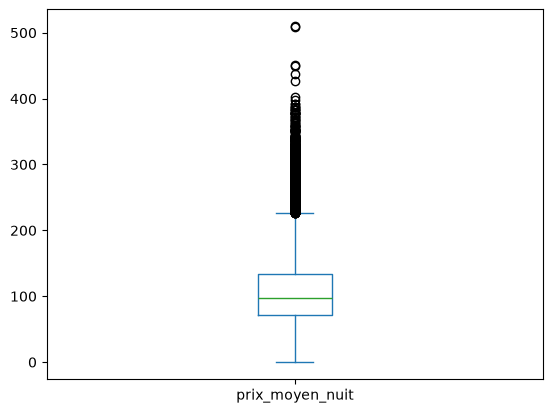

In [195]:
df["prix_moyen_nuit"].plot.box()

***Variable delai_reservation_jours***

<Axes: >

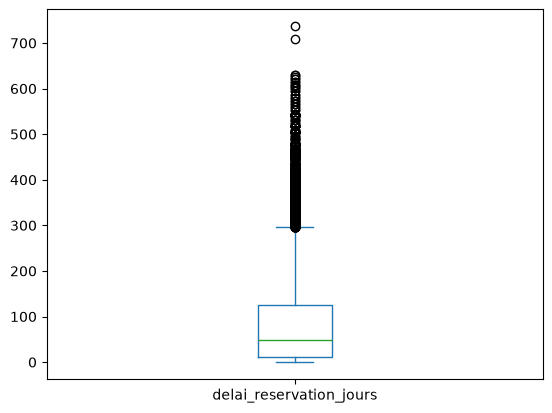

In [196]:
df["delai_reservation_jours"].plot.box()

***Variable nuits_semaine***

<Axes: >

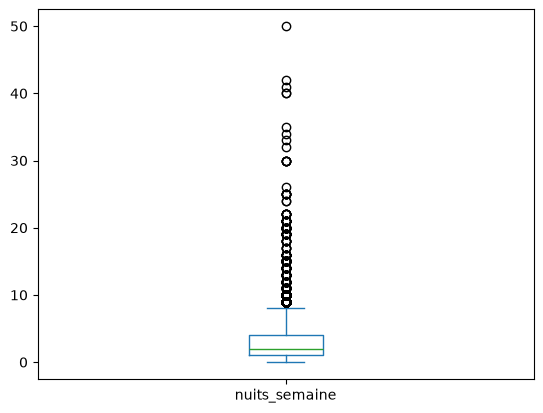

In [197]:
df["nuits_semaine"].plot.box()

***Variable nuits_weekend***

<Axes: >

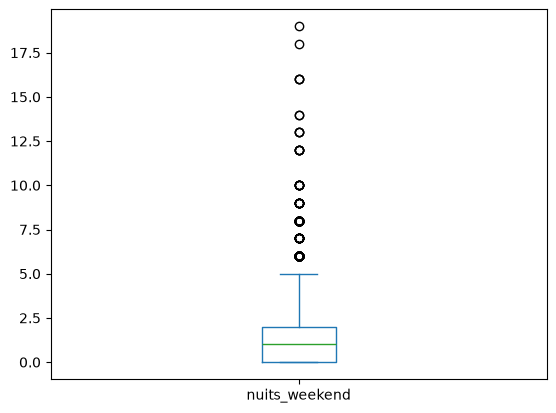

In [198]:
df["nuits_weekend"].plot.box()

***Revenue total***

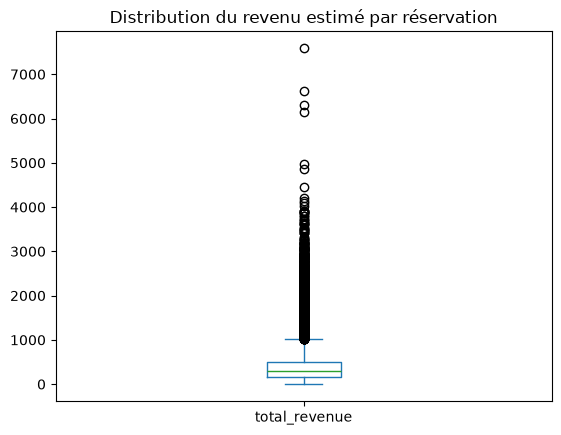

In [199]:
df["duree_sejour"] = df["nuits_semaine"] + df["nuits_weekend"]
df["total_revenue"] = (df["duree_sejour"] * df["prix_moyen_nuit"])
df["total_revenue"].plot.box()
plt.title("Distribution du revenu estimé par réservation")
plt.show()

***CA perdu à cause des annulations***

In [200]:
ca_potentiel = df["total_revenue"].sum()

ca_associe_annulations = df.loc[
    df["est_annule"] == 1, "total_revenue"
].sum()

print(f"Revenu potentiel estimé : {ca_potentiel:,.2f}")
print(
    "Revenu théorique associé aux annulations : "
    f"{ca_associe_annulations:,.2f}"
)

Revenu potentiel estimé : 34,455,603.11
Revenu théorique associé aux annulations : 11,478,642.98


In [201]:
ca_perdu = df[df['est_annule'] == 1]['total_revenue'].sum()
ca_total = df['total_revenue'].sum()
print(f"CA perdu : {ca_perdu:,.0f} ({ca_perdu/ca_total*100:.1f}% du CA potentiel)")

CA perdu : 11,478,643 (33.3% du CA potentiel)


## **Traitement des incohérences**

***Réservtions fantômes***

In [202]:
variables = ["adultes", "enfants", "bebes"]
hotel = ["hotel"]
df_reservation_fantome = df[variables].copy()

In [203]:
condition_zero = (df_reservation_fantome == 0).all(axis=1)
condition_hotel = df['hotel'].isin(['City Hotel', 'Resort Hotel'])
df_filtre = df_reservation_fantome[condition_zero & condition_hotel]

In [204]:
condition_sans_client = (
    (df["adultes"] == 0) &
    (df["enfants"].fillna(0) == 0) &
    (df["bebes"] == 0)
)

df_reservation_fantome = df.loc[condition_sans_client]

print("Réservations sans client :", len(df_reservation_fantome))

display(df_reservation_fantome.head(10))

Réservations sans client : 166


,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation,duree_sejour,total_revenue
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,1,No Deposit,NaN,174.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06,3,0.0
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,0,No Deposit,NaN,174.0,0,Transient,0.0,0,0,Check-Out,2015-10-12,0,0.0
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,0.0,0,SC,ESP,Groups,TA/TO,0,0,0,A,C,0,No Deposit,38.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23,3,0.0
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,A,1,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04,5,0.0
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,C,1,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05,6,0.0
4127,Resort Hotel,1,0,2016,February,8,15,0,0,0,0.0,0,SC,NaN,Offline TA/TO,TA/TO,0,0,0,P,P,0,No Deposit,NaN,383.0,0,Transient,0.0,0,0,Canceled,2016-02-15,0,0.0
9376,Resort Hotel,1,0,2016,November,48,21,0,0,0,0.0,0,SC,NaN,Offline TA/TO,TA/TO,0,0,0,P,P,0,No Deposit,NaN,386.0,0,Group,0.0,0,0,Canceled,2016-11-21,0,0.0
31765,Resort Hotel,0,31,2016,December,53,27,2,8,0,0.0,0,BB,PRT,Direct,Direct,0,0,0,D,D,3,No Deposit,NaN,NaN,0,Transient,28.0,1,0,Check-Out,2017-01-06,10,280.0
32029,Resort Hotel,0,4,2017,January,2,14,0,1,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,G,0,No Deposit,168.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-01-15,1,0.0
32827,Resort Hotel,0,46,2017,January,4,25,3,9,0,0.0,0,SC,FRA,Direct,Direct,0,0,0,A,I,8,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2017-02-06,12,0.0


In [205]:
df = df.drop(
    df[
        (df['adultes'] == 0) &
        (df['enfants'] == 0) &
        (df['bebes'] == 0)
    ].index
)

In [206]:
len(df_filtre)

166

##### Suppression des réservations sans adultes, ni enfants, ni bébés.

***Séjours impossible ((nuits_weekend + nuits_semaine) = 0 MAIS le statut n'est pas une annulation.***

In [238]:
condition_zero_nuit = (df['nuits_semaine'] == 0) & (df['nuits_weekend'] == 0)
condition_non_annulee = df['est_annule'] == 0

In [239]:
df_anomalies_nuits = df[condition_zero_nuit & condition_non_annulee]

df_anomalies_nuits

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation,duree_sejour,total_revenue,date_arrivee,lead_time_bins,tranche_delai,num_mois,periode,type_sejour
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0.0,2015-07-01,330,181-360 jours,7,2015-07-01,0 nuit
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0.0,2015-07-01,720,Plus de 360 jours,7,2015-07-01,0 nuit
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,H,0,No Deposit,240.0,NaN,0,Transient,0.0,0,2,Check-Out,2015-07-06,0,0.0,2015-07-06,90,91-180 jours,7,2015-07-01,0 nuit
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,0.0,0,BB,PRT,Direct,Direct,0,0,0,E,H,0,No Deposit,250.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-06,0,0.0,2015-07-06,0,0-7 jours,7,2015-07-01,0 nuit
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-07,0,0.0,2015-07-07,0,8-30 jours,7,2015-07-01,0 nuit
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115483,City Hotel,0,15,2017,July,27,6,0,0,1,0.0,0,SC,FRA,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-07-06,0,0.0,2017-07-06,0,8-30 jours,7,2017-07-01,0 nuit
117701,City Hotel,0,0,2017,August,32,8,0,0,2,0.0,0,BB,PRT,Offline TA/TO,TA/TO,1,0,0,A,A,0,No Deposit,262.0,NaN,0,Transient,0.0,0,0,Check-Out,2017-08-08,0,0.0,2017-08-08,0,0-7 jours,8,2017-08-01,0 nuit
118029,City Hotel,0,0,2017,August,33,14,0,0,2,0.0,0,BB,PRT,Direct,Direct,1,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2017-08-14,0,0.0,2017-08-14,0,0-7 jours,8,2017-08-01,0 nuit
118631,City Hotel,0,78,2017,August,34,23,0,0,1,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,K,7,No Deposit,98.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,0,0.0,2017-08-23,60,61-90 jours,8,2017-08-01,0 nuit


In [240]:
# Seconde vérification
condition_zero_nuit = (
    (df["nuits_semaine"] == 0) &
    (df["nuits_weekend"] == 0)
)

condition_non_annulee = df["est_annule"] == 0

df_anomalies_nuits = df.loc[
    condition_zero_nuit & condition_non_annulee
]

print(
    "Réservations non annulées sans nuit :",
    len(df_anomalies_nuits)
)

display(df_anomalies_nuits.head(10))

Réservations non annulées sans nuit : 568


,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation,duree_sejour,total_revenue,date_arrivee,lead_time_bins,tranche_delai,num_mois,periode,type_sejour
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0.0,2015-07-01,330,181-360 jours,7,2015-07-01,0 nuit
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0.0,2015-07-01,720,Plus de 360 jours,7,2015-07-01,0 nuit
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,H,0,No Deposit,240.0,NaN,0,Transient,0.0,0,2,Check-Out,2015-07-06,0,0.0,2015-07-06,90,91-180 jours,7,2015-07-01,0 nuit
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,0.0,0,BB,PRT,Direct,Direct,0,0,0,E,H,0,No Deposit,250.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-06,0,0.0,2015-07-06,0,0-7 jours,7,2015-07-01,0 nuit
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-07,0,0.0,2015-07-07,0,8-30 jours,7,2015-07-01,0 nuit
197,Resort Hotel,0,8,2015,July,28,7,0,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,E,0,No Deposit,240.0,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-07,0,0.0,2015-07-07,0,8-30 jours,7,2015-07-01,0 nuit
459,Resort Hotel,0,6,2015,July,29,17,0,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-17,0,0.0,2015-07-17,0,0-7 jours,7,2015-07-01,0 nuit
568,Resort Hotel,0,0,2015,July,30,20,0,0,1,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,I,0,No Deposit,5.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-20,0,0.0,2015-07-20,0,0-7 jours,7,2015-07-01,0 nuit
569,Resort Hotel,0,0,2015,July,30,20,0,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,I,0,No Deposit,241.0,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-20,0,0.0,2015-07-20,0,0-7 jours,7,2015-07-01,0 nuit
618,Resort Hotel,0,16,2015,July,30,23,0,0,2,2.0,0,BB,PRT,Online TA,TA/TO,0,0,0,C,I,0,No Deposit,242.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-23,0,0.0,2015-07-23,0,8-30 jours,7,2015-07-01,0 nuit


In [246]:
sans_nuit = (df["nuits_semaine"] + df["nuits_weekend"]) == 0
print("Séjours sans nuit supprimés :", sans_nuit.sum())
df = df[~sans_nuit]

Séjours sans nuit supprimés : 591


In [247]:
print("Lignes :", len(df))                                        # 86 637 attendu
print("Prix nuls gardés :", (df["prix_moyen_nuit"] == 0).sum())   # 1 052 attendu

Lignes : 86637
Prix nuls gardés : 1052


##### Présence d'aucune ligne concernant des réservations sans nuit.

***Date to datetime***

In [210]:
# Conversion des dates
df['date_statut_reservation'] = pd.to_datetime(
    df['date_statut_reservation'],
    errors='coerce'
)

# Reconstruction de la date d'arrivée
df['date_arrivee'] = pd.to_datetime(
    df['annee_arrivee'].astype(str) + '-' +
    df['mois_arrivee'].astype(str) + '-' +
    df['jour_arrivee'].astype(str),
    errors='coerce'
)

# Vérification des dates invalides
print("Dates de statut invalides :", df['date_statut_reservation'].isna().sum())
print("Dates d'arrivée invalides :", df['date_arrivee'].isna().sum())

# Vérification de cohérence
incoherence = df['date_statut_reservation'] < df['date_arrivee']
print("Nombre total d'incohérences :", incoherence.sum())

Dates de statut invalides : 0
Dates d'arrivée invalides : 0
Nombre total d'incohérences : 22244


In [211]:
df['date_statut_reservation']

0        2015-07-01
1        2015-07-01
2        2015-07-02
3        2015-07-02
4        2015-07-03
            ...    
119385   2017-09-06
119386   2017-09-07
119387   2017-09-07
119388   2017-09-07
119389   2017-09-07
Name: date_statut_reservation, Length: 87228, dtype: datetime64[us]

##### Une réservation est souvent enregistrée avant l’arrivée du client, donc avoir in nombre d'incohérence est normale si date_statut_reservation correspond à la date de réservation.

# 4. Visualisation

## **Distribution de différentes variables**

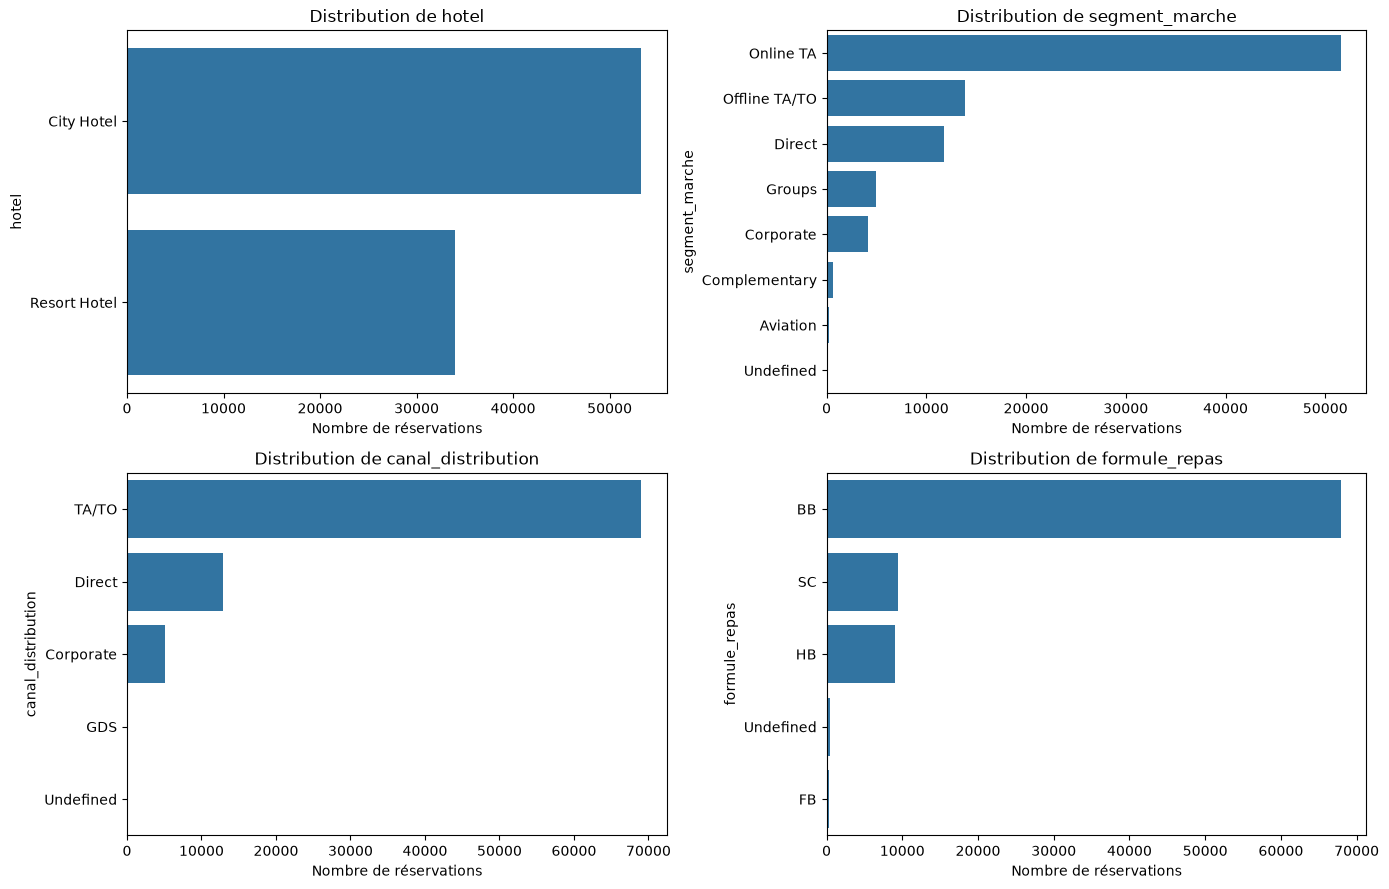

In [212]:
colonnes_cat = ["hotel", "segment_marche", "canal_distribution", "formule_repas"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, ax in zip(colonnes_cat, axes.flatten()):
    ordre = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=ordre, ax=ax)
    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel("Nombre de réservations")
plt.tight_layout()
plt.show()

## **Top Pays**

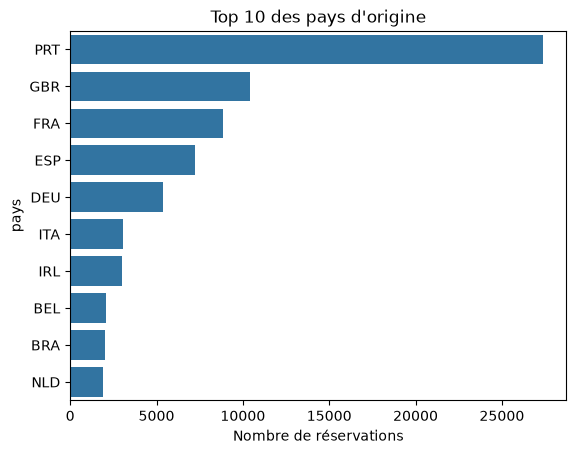

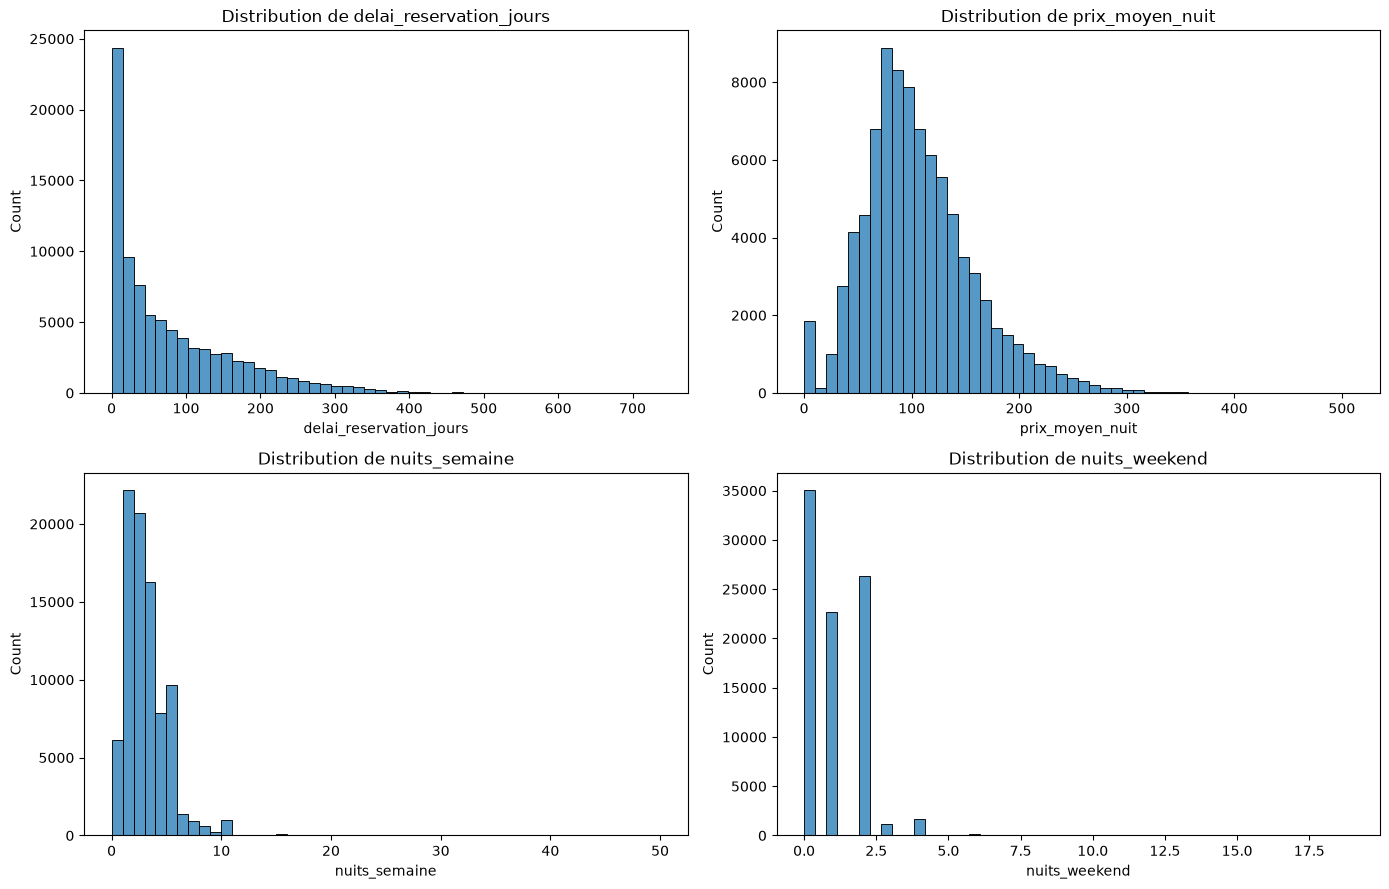

,count,mean,std,min,25%,50%,75%,max
delai_reservation_jours,87228.0,79.970216,86.058654,0.0,11.00,49.0,125.0,737.0
prix_moyen_nuit,87228.0,106.458639,51.881832,0.0,72.25,98.2,134.1,510.0
nuits_semaine,87228.0,2.623905,2.039814,0.0,1.00,2.0,4.0,50.0
nuits_weekend,87228.0,1.004586,1.027365,0.0,0.00,1.0,2.0,19.0
adultes,87228.0,1.879362,0.621731,0.0,2.00,2.0,2.0,55.0
enfants,87224.0,0.138907,0.456279,0.0,0.00,0.0,0.0,10.0
bebes,87228.0,0.010845,0.113705,0.0,0.00,0.0,0.0,10.0


In [213]:
top_pays = df["pays"].value_counts().head(10)
sns.barplot(x=top_pays.values, y=top_pays.index)
plt.title("Top 10 des pays d'origine")
plt.xlabel("Nombre de réservations")
plt.show()
colonnes_num = ["delai_reservation_jours", "prix_moyen_nuit", "nuits_semaine", "nuits_weekend"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, ax in zip(colonnes_num, axes.flatten()):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(f"Distribution de {col}")
plt.tight_layout()
plt.show()

df[colonnes_num + ["adultes", "enfants", "bebes"]].describe().T

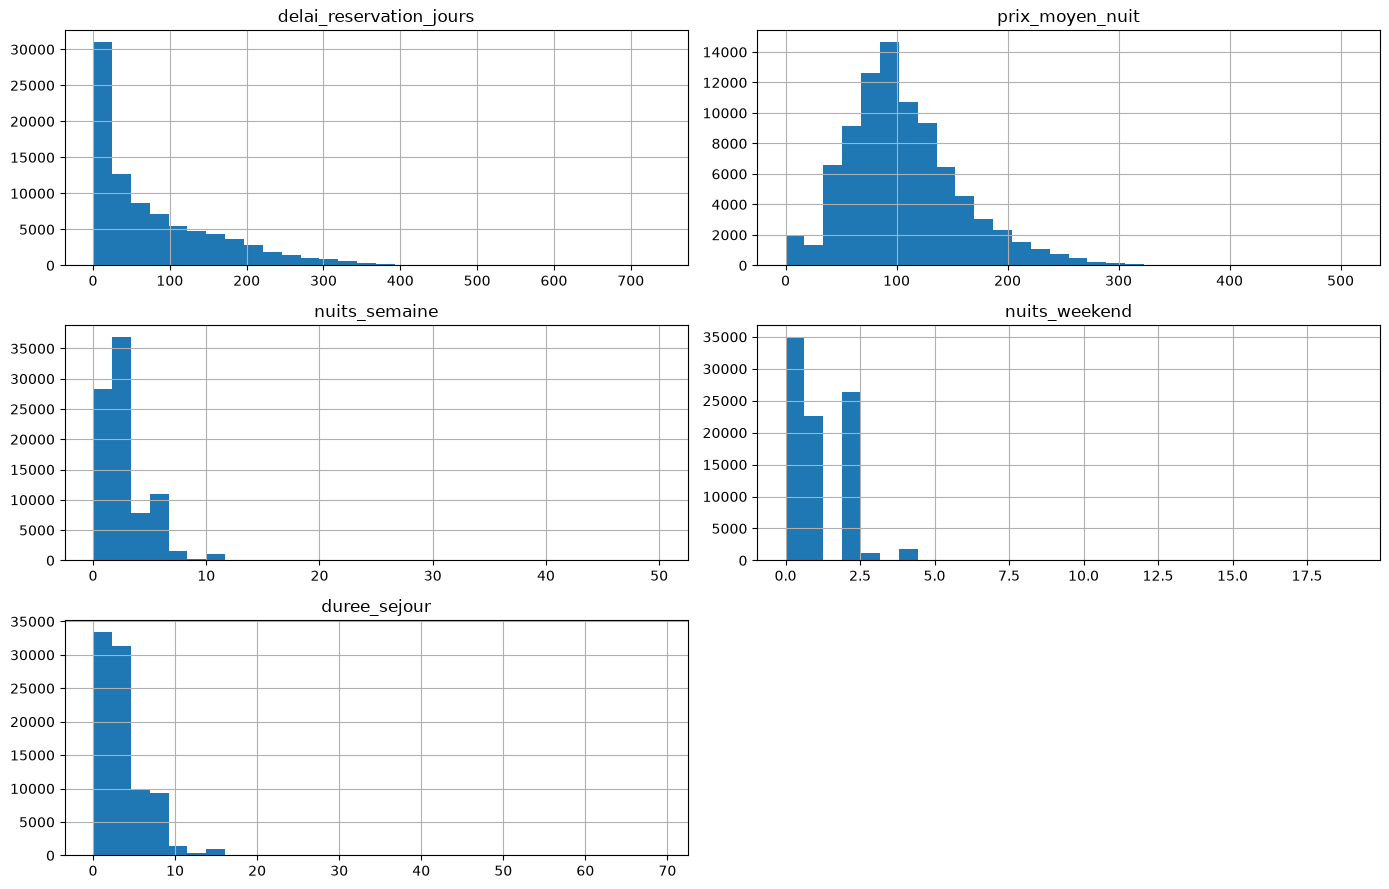

,count,mean,std,min,25%,50%,75%,max
delai_reservation_jours,87228.0,79.970216,86.058654,0.0,11.00,49.0,125.0,737.0
prix_moyen_nuit,87228.0,106.458639,51.881832,0.0,72.25,98.2,134.1,510.0
nuits_semaine,87228.0,2.623905,2.039814,0.0,1.00,2.0,4.0,50.0
nuits_weekend,87228.0,1.004586,1.027365,0.0,0.00,1.0,2.0,19.0
duree_sejour,87228.0,3.628491,2.742880,0.0,2.00,3.0,5.0,69.0
adultes,87228.0,1.879362,0.621731,0.0,2.00,2.0,2.0,55.0
enfants,87224.0,0.138907,0.456279,0.0,0.00,0.0,0.0,10.0
bebes,87228.0,0.010845,0.113705,0.0,0.00,0.0,0.0,10.0


In [214]:
colonnes_num = [
    "delai_reservation_jours",
    "prix_moyen_nuit",
    "nuits_semaine",
    "nuits_weekend",
    "duree_sejour"
]

df[colonnes_num].hist(figsize=(14, 9), bins=30)
plt.tight_layout()
plt.show()

display(df[colonnes_num + ["adultes", "enfants", "bebes"]].describe().T)

## **Le taux d'annulation selon le délai de réservation**

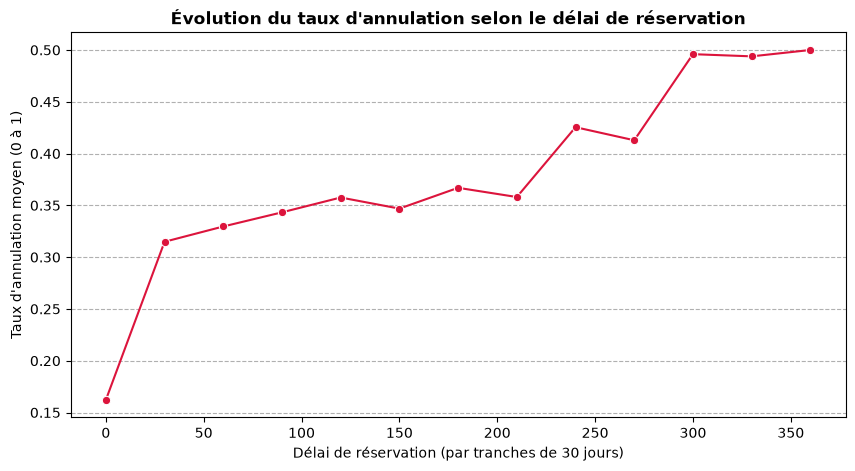

In [215]:
plt.figure(figsize=(10, 5))

df['lead_time_bins'] = (df['delai_reservation_jours'] // 30) * 30             
df_filtered = df[df['delai_reservation_jours'] <= 360]                        # filtrage pour ne pas aller dans les extrêmes (max 360 jours)


sns.lineplot(
    data=df_filtered, 
    x='lead_time_bins', 
    y='est_annule', 
    marker='o', 
    color='crimson', 
    errorbar=None 
)

plt.title("Évolution du taux d'annulation selon le délai de réservation", fontsize=12, fontweight='bold')
plt.xlabel("Délai de réservation (par tranches de 30 jours)")
plt.ylabel("Taux d'annulation moyen (0 à 1)")
plt.grid(axis='y', linestyle='--')
plt.show()


#### Ce graphique montre une tendance à la hausse du taux d’annulation en fonction du délai de réservation. Plus une réservation est effectuée longtemps à l’avance, plus le risque d’annulation semble important. Le taux passe d’environ 16 % pour les réservations de dernière minute à près de 50 % pour celles effectuées 300 jours à l’avance. On observe donc une corrélation positive entre le délai de réservation et le taux d’annulation, malgré quelques légères fluctuations.

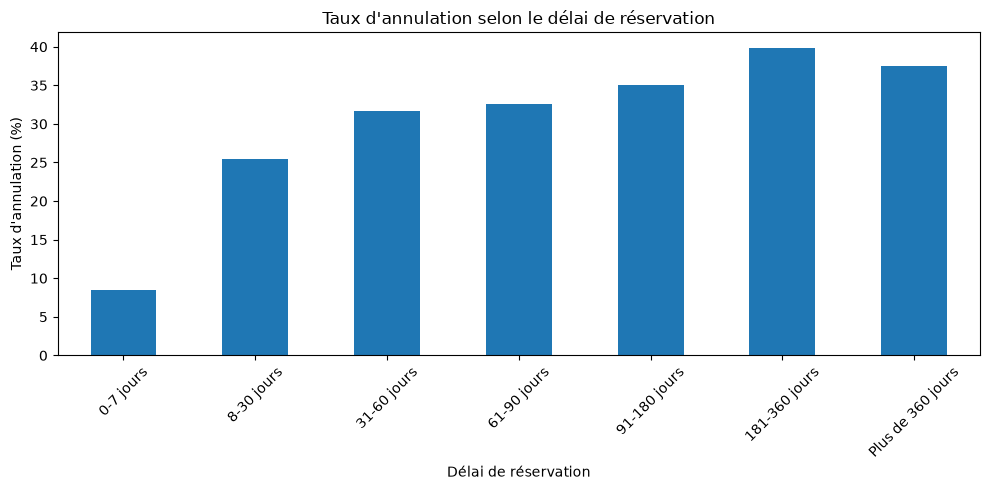

tranche_delai
0-7 jours             8.42
8-30 jours           25.39
31-60 jours          31.66
61-90 jours          32.58
91-180 jours         35.01
181-360 jours        39.88
Plus de 360 jours    37.50
Name: est_annule, dtype: float64

In [216]:
df["tranche_delai"] = pd.cut(
    df["delai_reservation_jours"],
    bins=[-1, 7, 30, 60, 90, 180, 360, float("inf")],
    labels=[
        "0-7 jours", "8-30 jours", "31-60 jours",
        "61-90 jours", "91-180 jours",
        "181-360 jours", "Plus de 360 jours"
    ]
)

taux_delai = (
    df.groupby("tranche_delai", observed=False)["est_annule"]
    .mean() * 100
)

taux_delai.plot(kind="bar", figsize=(10, 5))

plt.title("Taux d'annulation selon le délai de réservation")
plt.xlabel("Délai de réservation")
plt.ylabel("Taux d'annulation (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(taux_delai.round(2))

#### Ce graphique met en évidence une tendance claire : plus une réservation est effectuée à l'avance, plus le risque d'annulation est élevé. Les réservations de dernière minute (0-7 jours) sont très fiables, avec un taux d'annulation d'environ 8%. À l'inverse, le taux grimpe fortement dès que le délai dépasse une semaine, pour atteindre son maximum (environ 40%) sur les réservations faites 6 à 12 mois à l'avance. Au-delà d'un an, le taux redescend légèrement mais reste très élevé (autour de 37-38%).

## **Le taux d'annulation par mois**

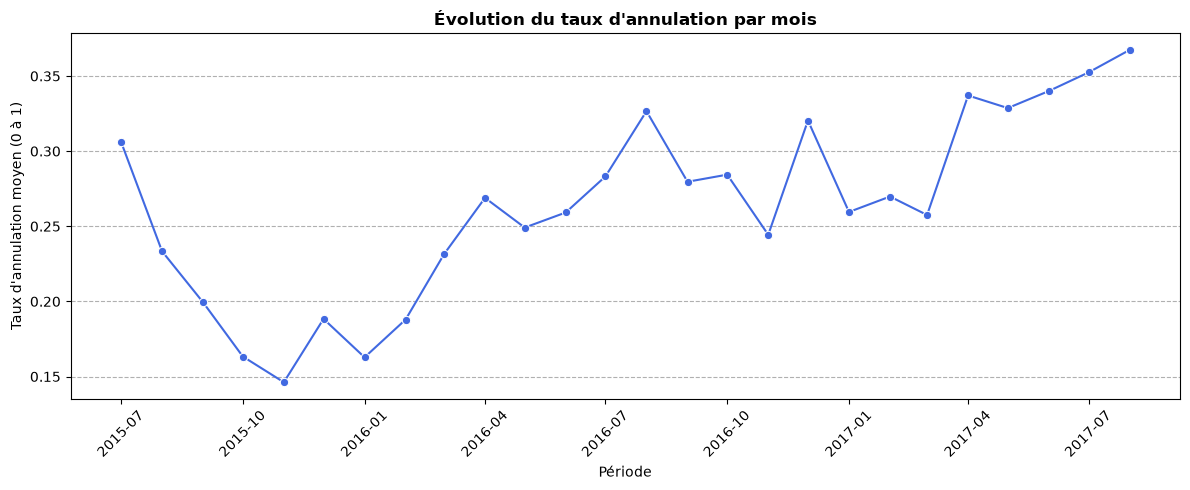

In [217]:
mois_trad = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12,
    'Janvier': 1, 'Février': 2, 'Mars': 3, 'Avril': 4, 'Mai': 5, 'Juin': 6,
    'Juillet': 7, 'Août': 8, 'Septembre': 9, 'Octobre': 10, 'Novembre': 11, 'Décembre': 12
}

# Si 'mois_arrivee' contient des chaînes de caractères, on applique la traduction
if df['mois_arrivee'].dtype == 'object':
    df['num_mois'] = df['mois_arrivee'].map(mois_trad)
else:
    df['num_mois'] = df['mois_arrivee']

# Création d'une colonne 'Date' au format Année-Mois pour un affichage chronologique propre
df['periode'] = pd.to_datetime(df['annee_arrivee'].astype(str) + '-' + df['num_mois'].astype(str) + '-01')
df_grouped_month = df.groupby('periode')['est_annule'].mean().reset_index()


plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_grouped_month, 
    x='periode', 
    y='est_annule', 
    marker='o', 
    color='royalblue'
)

plt.title("Évolution du taux d'annulation par mois", fontsize=12, fontweight='bold')
plt.xlabel("Période")
plt.ylabel("Taux d'annulation moyen (0 à 1)")
plt.grid(axis='y', linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Contrairement à ce qu'on pourrait pensee, ce graphique montre une tendance globale à la hausse du taux d'annulation sur la période 2015-2017. Le taux était plutôt bas en 2015 (entre 15% et 20% en fin d'année). Il augmente nettement en 2016 et reste élevé en 2017, dépassant régulièrement les 30%, avec des pics visibles. Le risque d'annulation s'est aggravé au fil du temps dans les deux établissements (à voir en comparaison séparé ?).

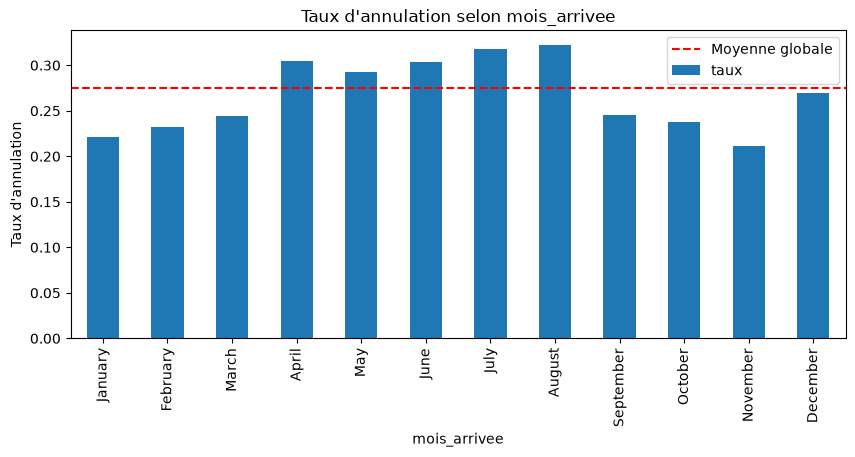

,taux,nb
mois_arrivee,,
January,0.221,4685
February,0.232,6083
March,0.244,7487
April,0.305,7900
May,0.293,8344
June,0.303,7756
July,0.318,10043
August,0.322,11242
September,0.246,6682


In [219]:
def taux_annulation(colonne, ordre=None):
    tab = df.groupby(colonne, observed=True)["est_annule"].agg(taux="mean", nb="count")
    if ordre is not None:
        tab = tab.reindex(ordre)
    ax = tab["taux"].plot(kind="bar", figsize=(10, 4))
    ax.axhline(df["est_annule"].mean(), color="red", linestyle="--", label="Moyenne globale")
    ax.set_ylabel("Taux d'annulation")
    ax.set_title(f"Taux d'annulation selon {colonne}")
    ax.legend()
    plt.show()
    return tab.round(3)

mois = ["January", "February", "March", "April", "May", "June", "July",
        "August", "September", "October", "November", "December"]
taux_annulation("mois_arrivee", ordre=mois)

#### Ce graphique met en évidence une forte saisonnalité du risque d'annulation selon la période de l'année. Les mois de forte activité (d'avril à août), les taux d'annulation sont les plus élevés, dépassant tous la moyenne globale (ligne rouge pointillée) pour culminer à plus de 32 % en août. À l'inverse, de septembre à mars, les taux sont plus faibles, avec un minimum à environ 21 % en novembre. On peut comprendre que les clients ont tendance à annuler beaucoup plus souvent pour des séjours prévus pendant la haute saison (période estivale).

## **Le taux d'annulation en fonction de la semaine/ week-end**

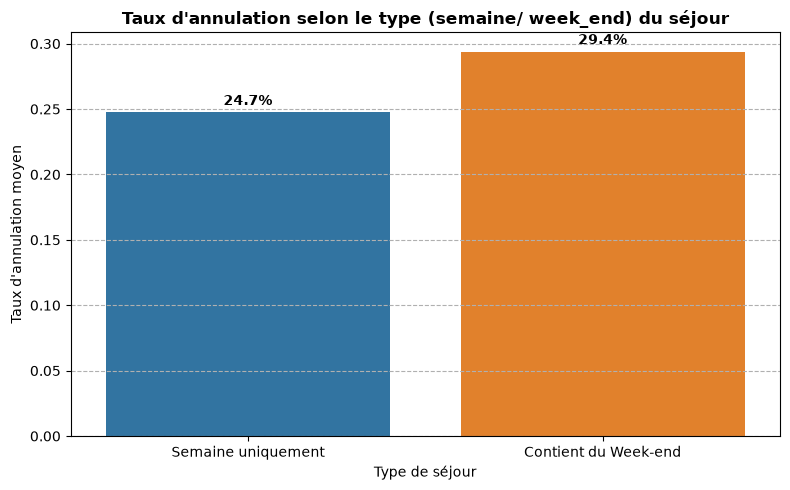

In [220]:
df['type_sejour'] = df['nuits_weekend'].apply(lambda x: 'Contient du Week-end' if x > 0 else 'Semaine uniquement')

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, 
    x='type_sejour', 
    y='est_annule', 
    hue='type_sejour',       
    palette=['#1f77b4', '#ff7f0e'], 
    legend=False,            
    errorbar=None 
)

plt.title("Taux d'annulation selon le type (semaine/ week_end) du séjour", fontsize=12, fontweight='bold')
plt.xlabel("Type de séjour")
plt.ylabel("Taux d'annulation moyen")
plt.grid(axis='y', linestyle='--')

# Ajouter les pourcentages au-dessus des barres
ax = plt.gca()
for p in ax.patches:
    # On vérifie que la barre a une hauteur valide pour éviter les erreurs d'affichage
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

#### Le risque d'annulation est plus important lorsque le séjour inclut un week-end. Cela peut s'expliquer par le fait que ces séjours correspondent souvent à des projets de loisirs (plus flexibles et donc plus susceptibles d'être annulés) ou à des périodes plus demandées où les clients réservent en "sécurité" tout en continuant à chercher d'autres options.

## **Le taux d'annulation en fonction du type de séjour**

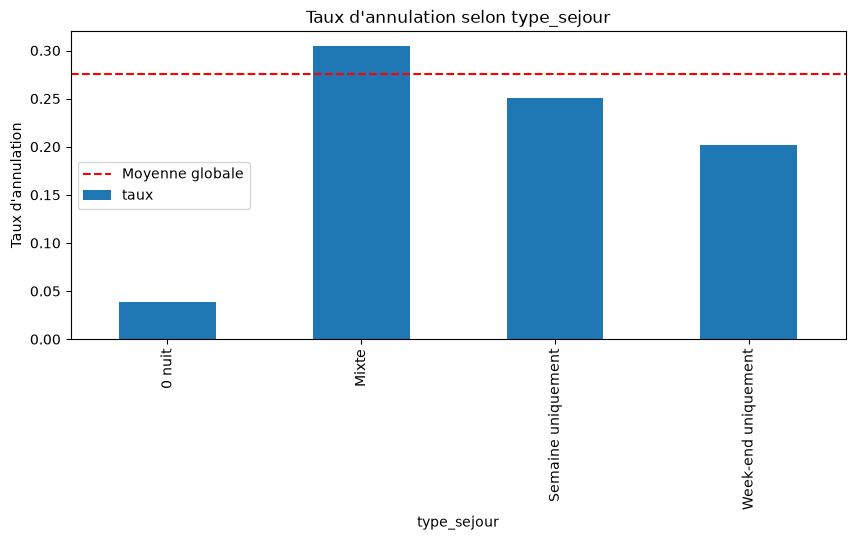

,taux,nb
type_sejour,,
0 nuit,0.039,591
Mixte,0.305,46650
Semaine uniquement,0.251,34466
Week-end uniquement,0.202,5521


In [221]:
df["type_sejour"] = np.select(
    [(df["nuits_semaine"] + df["nuits_weekend"]) == 0, df["nuits_semaine"] == 0, df["nuits_weekend"] == 0],
    ["0 nuit", "Week-end uniquement", "Semaine uniquement"], default="Mixte")
taux_annulation("type_sejour")

#### On observe ici des disparités très nettes entre les séjours mixtes (semaine + week-end) qui sont les plus risqués, avec le taux d'annulation le plus élevé, les séjours en semaine qui affiche uniquement un taux intermédiaire, et entre les séjours de week-end qui sont un peu plus fiables. Les 0 nuits ne sont pas comptabiliser (supprimer dans la phase d'EDA). Donc plus un séjour est long et combine plusieurs types de nuits (mixte), plus le risque d'annulation est important. À l'inverse, les séjours courts ou atypiques sont beaucoup plus fiables.

## **Le taux d'annulation en fonction du type d'acompte & du segment de marché**

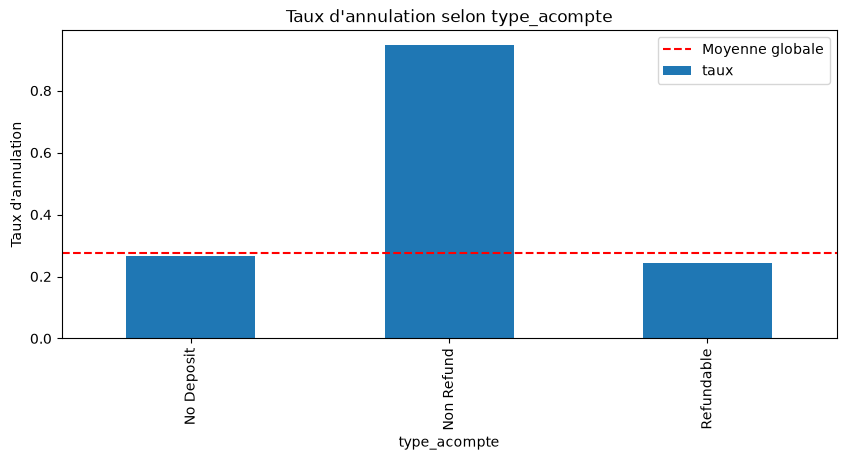

,taux,nb
type_acompte,,
No Deposit,0.267,86084
Non Refund,0.947,1037
Refundable,0.243,107


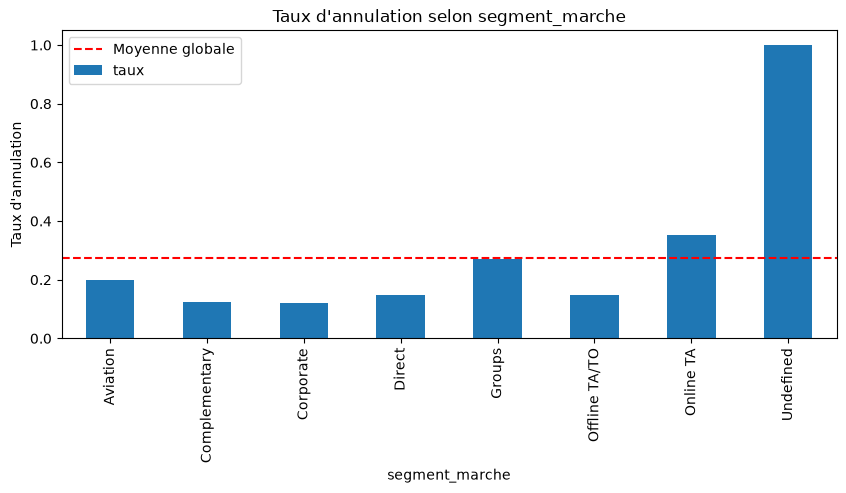

,taux,nb
segment_marche,,
Aviation,0.199,226
Complementary,0.123,692
Corporate,0.121,4200
Direct,0.147,11780
Groups,0.271,4921
Offline TA/TO,0.148,13854
Online TA,0.354,51553
Undefined,1.000,2


In [224]:
display(taux_annulation("type_acompte"))
display(taux_annulation("segment_marche"))

#### Pour le graphique du taux d'annulation selon le type d'acompte, il révèle un comportement surprenant mais logique : le type d'acompte "Non Refund" (non remboursable) affiche un taux d'annulation extrêmement élevé (94,7 %), bien au-dessus de la moyenne globale. À l'inverse, les réservations sans acompte ("No Deposit") ou remboursables ("Refundable") tournent autour de 24 à 27 %. Il faut supposer que puisque le dépôt est non remboursable, les clients qui annulent ont probablement déjà payé (ou savent qu'ils perdront leur argent), ce qui suggère que ces réservations sont souvent faites par des clients qui ne sont pas sûrs de venir et qui préfèrent sécuriser une chambre "au cas où", quitte à perdre l'acompte. Ensuite, concernant le taux d'annulation selon le segment de marché, il y a des différences sont énormes selon le canal d'origine de la réservation :
#### - Le segment "Online TA" (Agences en ligne type Booking/Expedia) est le plus risqué, avec un taux de 35,4 % et un volume massif (plus de 51 000 réservations). C'est le principal moteur d'annulations.
#### - Les segments "Corporate", "Direct" et "Offline TA/TO" possèdent des taux faibles (entre 12 % et 15 %). Les clients directs et d'affaires annulent beaucoup moins.
#### - Le segment "Groupes" est légèrement au-dessus de la moyenne (27 %).
#### Les réservations passées via des agences en ligne (Online TA) avec des politiques d'annulation flexibles (ou des acomptes non remboursables) constituent le principal point de fuite pour l'hôtel. À l'inverse, les réservations directes et professionnelles sont beaucoup plus stables.

## **La saisonnalité des prix moyens par type d'hôtel**

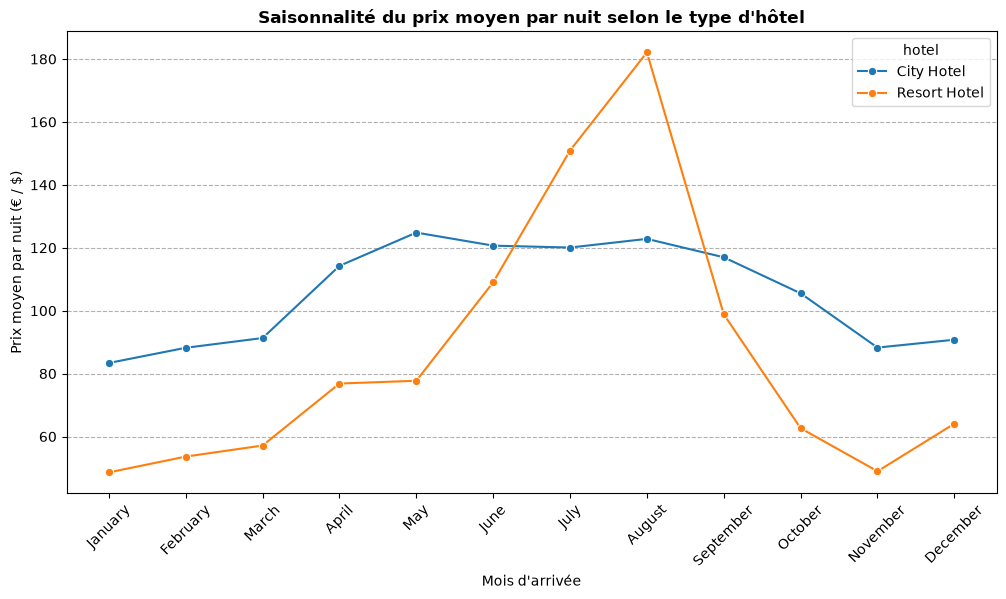

In [225]:
ordre_mois = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

# Transformatio la colonne en catégorie ordonnée pour forcer Pandas et Seaborn à respecter cet ordre sur l'axe X
df['mois_arrivee'] = pd.Categorical(df['mois_arrivee'], categories=ordre_mois, ordered=True)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df[df['est_annule'] == 0], 
    x='mois_arrivee', 
    y='prix_moyen_nuit', 
    hue='hotel', 
    hue_order=['City Hotel', 'Resort Hotel'], 
    marker='o', 
    errorbar=None)

plt.title("Saisonnalité du prix moyen par nuit selon le type d'hôtel", fontsize=12, fontweight='bold')
plt.xlabel("Mois d'arrivée")
plt.ylabel("Prix moyen par nuit (€ / $)")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

#### Le City Hotel a des prix très stables toute l'année. Ils oscillent globalement entre 85 € et 125 €, avec un léger pic au printemps (mai) et une baisse en automne (octobre/novembre). Il vise une clientèle plutôt professionnelle ou urbaine, moins sensible aux vacances.
#### Le Resort Hotel présente une saisonnalité extrême. Ses prix sont très bas en hiver (environ 50 € en janvier/novembre) et explosent littéralement en été, atteignant un sommet d'environ 180 € en août. C'est la logique classique des vacances : les tarifs s'envolent quand la demande est la plus forte.
#### On peut comprendre que City Hotel applique une politique de prix lissée sur l'année, tandis que le Resort Hotel mise tout sur la haute saison estivale pour maximiser ses revenus.

## **Volume des Réservations vs Annulations par Type d'Hôtel**

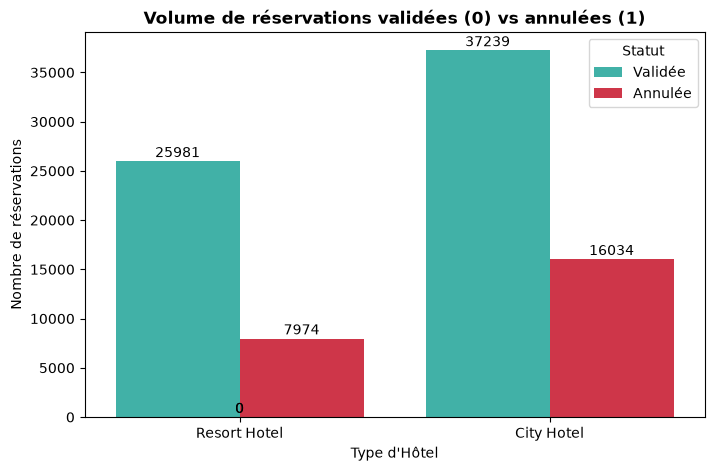

In [226]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='hotel', hue='est_annule', palette=['#2ec4b6', '#e71d36'])
plt.title("Volume de réservations validées (0) vs annulées (1)", fontsize=12, fontweight='bold')
plt.xlabel("Type d'Hôtel")
plt.ylabel("Nombre de réservations")
plt.legend(title="Statut", labels=["Validée", "Annulée"])


for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 3), textcoords='offset points')
plt.show()

#### Le City Hotel à le plus de réservations (plus de 53 000 au total). Il affiche 37 239 réservations validées et 16 034 annulées. Le Resort Hotel a un volume global plus faible (près de 34 000), avec 25 981 validées et 7 974 annulées. En valeur absolue, le City Hotel génère deux fois plus d'annulations que le Resort Hotel (16 000 contre 8 000). Cependant, si l'on regarde la proportion, le City Hotel annule environ 30 % de ses réservations, contre environ 23,5 % pour le Resort Hotel. Le City Hotel est donc à la fois plus gros en volume et proportionnellement plus touché par les annulations.

## **La Répartition du Chiffre d'Affaires par Segment de Marché**

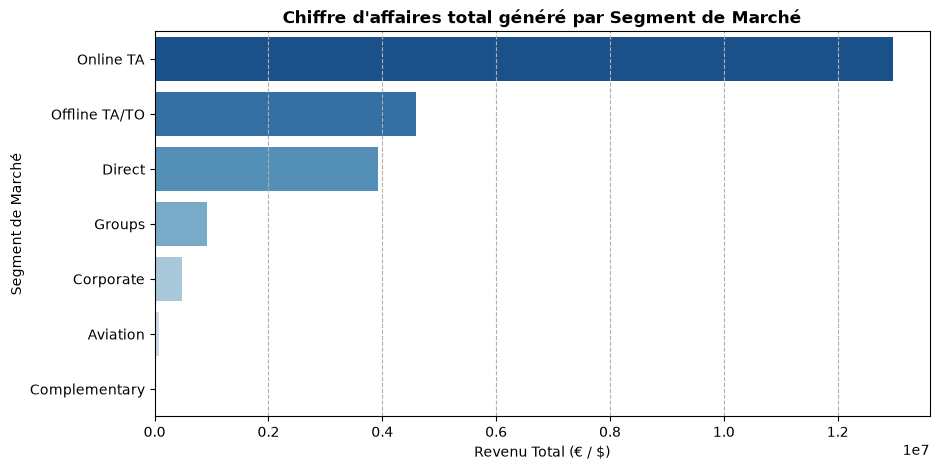

In [227]:
df['total_revenue'] = (df['nuits_weekend'] + df['nuits_semaine']) * df['prix_moyen_nuit']

# Somme des revenus par segment de marché (réservations non annulées)
revenue_by_segment = (
    df[df['est_annule'] == 0]
    .groupby('segment_marche')['total_revenue']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))


sns.barplot(
    x=revenue_by_segment.values, 
    y=revenue_by_segment.index, 
    hue=revenue_by_segment.index,  
    palette='Blues_r',
    legend=False                   
)

plt.title("Chiffre d'affaires total généré par Segment de Marché", fontsize=12, fontweight='bold')
plt.xlabel("Revenu Total (€ / $)")
plt.ylabel("Segment de Marché")
plt.grid(axis='x', linestyle='--')
plt.show()

#### Ce graphique montre que le chiffre d'affaires (calculé sur les réservations non annulées) est très fortement concentré sur le segment "Online TA" (les agences de voyage en ligne comme Booking ou Expedia). Online TA génère à lui seul plus de 13 millions d'euros/dollars, soit largement plus que tous les autres segments réunis. C'est le moteur économique principal de l'hôtel. Offline TA/TO (agences physiques) et Direct (réservations en direct) arrivent loin derrière, avec respectivement environ 4,5 millions et 4 millions. Les segments Groups, Corporate et Aviation génèrent des revenus beaucoup plus faibles. Enfin, le segment Complementary (chambres offertes) est logiquement à zéro, puisqu'il ne génère quasimment pas de revenus. Les hôtels sont économiquement très dépendant des plateformes de réservation en ligne. Bien que ce segment soit aussi celui qui annule le plus (comme vu précédemment), il reste de loin la principale source de revenus.

# 5. Création du nouveau fichier csv

In [229]:
df.to_csv('reservations_nettoyees.csv', index=False)

In [230]:
df_verif = pd.read_csv('reservations_nettoyees.csv')
df_verif

,hotel,est_annule,delai_reservation_jours,annee_arrivee,mois_arrivee,semaine_arrivee,jour_arrivee,nuits_weekend,nuits_semaine,adultes,enfants,bebes,formule_repas,pays,segment_marche,canal_distribution,client_fidele,annulations_precedentes,reservations_precedentes_non_annulees,type_chambre_reservee,type_chambre_attribuee,nb_modifications,type_acompte,id_agent,id_entreprise,jours_liste_attente,type_client,prix_moyen_nuit,places_parking,nb_demandes_speciales,statut_reservation,date_statut_reservation,duree_sejour,total_revenue,date_arrivee,lead_time_bins,tranche_delai,num_mois,periode,type_sejour
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0,0.00,2015-07-01,330,181-360 jours,7,2015-07-01,0 nuit
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0,0.00,2015-07-01,720,Plus de 360 jours,7,2015-07-01,0 nuit
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,75.00,2015-07-01,0,0-7 jours,7,2015-07-01,Semaine uniquement
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,1,75.00,2015-07-01,0,8-30 jours,7,2015-07-01,Semaine uniquement
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,2,196.00,2015-07-01,0,8-30 jours,7,2015-07-01,Semaine uniquement
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87223,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06,7,672.98,2017-08-30,0,8-30 jours,8,2017-08-01,Mixte
87224,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07,7,1578.01,2017-08-31,90,91-180 jours,8,2017-08-01,Mixte
87225,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07,7,1103.97,2017-08-31,30,31-60 jours,8,2017-08-01,Mixte
87226,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07,7,730.80,2017-08-31,90,91-180 jours,8,2017-08-01,Mixte


#

## **INFORMATIONS GÉNÉRALES**

Le dataset contient initialement 119 390 lignes et 32 colonnes.

Les doublons et catégories non définies ont été examinés et traités. Les valeurs manquantes on été laissé telles quelles.

Les distributions et taux d'annulation permettent de comparer les hôtels, les segments de marché, les délais et les périodes.

Le revenu calculé est une estimation et ne correspond pas nécessairement aux encaissements réels.

#

# 6. Phase préparatoire SQL

## **Questions possible pour la partie SQL**

#### Quel est le taux d'annulation par hôtel ?
#### Quel est le taux d'annulation par tranche de délais
#### Le type d'acompte versé à la réservation modifie-t-il le risque d'annulation et la politique de dépôt est-elle un levier pour sécuriser l'occupation dans chaque hôtel ?
#### Quel est le taux d'annulation par segment et par hôtel ainsi que le nombre de réservation ?
#### Quels segments de marché génèrent le plus de réservations ?
#### Quels canaux de distribution sont associés aux taux d'annulation les plus élevés ?
#### Quels mois concentrent le plus d'arrivées ?
#### Quelle est la durée moyenne des séjours ?
#### Quel est le prix moyen par nuit selon le type d'hôtel ?